# Machine Learning Zoomcamp 2026 - Homework 2: Regression

Dataset: **2026 Car Fuel Efficiency** (`car_fuel_efficiency_2026.csv`)
Target: `'fuel_efficiency_mpg'`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

## 1. Download and Prepare the Dataset

We use only the specified columns:
* `'engine_displacement'`
* `'horsepower'`
* `'vehicle_weight'`
* `'model_year'`
* `'fuel_efficiency_mpg'`

In [2]:
data_url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'

try:
    df_raw = pd.read_csv('car_fuel_efficiency_2026.csv')
except FileNotFoundError:
    df_raw = pd.read_csv(data_url)

selected_columns = [
    'engine_displacement',
    'horsepower',
    'vehicle_weight',
    'model_year',
    'fuel_efficiency_mpg'
]

df = df_raw[selected_columns].copy()
features = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']
target = 'fuel_efficiency_mpg'

df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


## 2. Exploratory Data Analysis & Question 1

Check target distribution and find which column contains missing values.

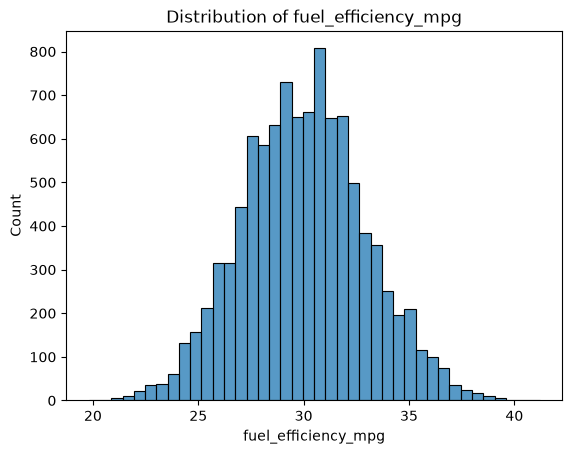

In [3]:
sns.histplot(df[target], bins=40)
plt.title('Distribution of fuel_efficiency_mpg')
plt.show()

In [4]:
# Question 1: Missing values
print("Missing values per column:")
print(df.isnull().sum())

missing_col = df[features].isnull().sum().idxmax()
print(f"\n>>> Question 1 Answer: {missing_col}")

Missing values per column:
engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

>>> Question 1 Answer: horsepower


## 3. Question 2: Median for Horsepower

In [5]:
# Question 2: Median (50% percentile) for variable 'horsepower'
median_hp = df['horsepower'].median()
print(f">>> Question 2 Answer: {median_hp}")

>>> Question 2 Answer: 254.0


## 4. Normal Equation & Validation Framework Functions

Implementation of linear regression with and without regularization, RMSE calculation, and dataset split.

In [6]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    
    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    
    XTX = X.T.dot(X)
    reg = r * np.eye(XTX.shape[0])
    XTX = XTX + reg
    
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

def rmse(y, y_pred):
    error = y_pred - y
    mse = (error ** 2).mean()
    return np.sqrt(mse)

def split_dataset(dataframe, seed=42):
    n = len(dataframe)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    train = dataframe.iloc[idx[:n_train]].copy().reset_index(drop=True)
    val = dataframe.iloc[idx[n_train:n_train + n_val]].copy().reset_index(drop=True)
    test = dataframe.iloc[idx[n_train + n_val:]].copy().reset_index(drop=True)

    return train, val, test

## 5. Question 3: Filling Missing Values (0 vs Mean)

Compare filling with `0` vs `mean` (computed exclusively on training set) using seed 42.

In [7]:
df_train, df_val, df_test = split_dataset(df, seed=42)

y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

# Option A: Fill with 0
X_train_0 = df_train[features].fillna(0).values
w0_0, w_0 = train_linear_regression(X_train_0, y_train)
X_val_0 = df_val[features].fillna(0).values
y_pred_0 = w0_0 + X_val_0.dot(w_0)
score_0 = round(rmse(y_val, y_pred_0), 3)

# Option B: Fill with mean of training set
mean_val = df_train[missing_col].mean()
X_train_mean = df_train[features].fillna(mean_val).values
w0_m, w_m = train_linear_regression(X_train_mean, y_train)
X_val_mean = df_val[features].fillna(mean_val).values
y_pred_mean = w0_m + X_val_mean.dot(w_m)
score_mean = round(rmse(y_val, y_pred_mean), 3)

print(f"RMSE filling with 0:    {score_0}")
print(f"RMSE filling with mean: {score_mean}")

if score_0 < score_mean:
    q3_ans = "With 0"
elif score_mean < score_0:
    q3_ans = "With mean"
else:
    q3_ans = "Both are equally good"

print(f"\n>>> Question 3 Answer: {q3_ans}")

RMSE filling with 0:    2.205
RMSE filling with mean: 2.202

>>> Question 3 Answer: With mean


## 6. Question 4: Regularization Parameter Tuning

Fill missing values with 0. Evaluate regularization values `r in [0, 0.01, 0.1, 1, 5, 10, 100]`.

In [8]:
r_candidates = [0, 0.01, 0.1, 1, 5, 10, 100]
scores_r = {}

for r in r_candidates:
    w0_r, w_r = train_linear_regression_reg(X_train_0, y_train, r=r)
    y_pred_r = w0_r + X_val_0.dot(w_r)
    score_r = round(rmse(y_val, y_pred_r), 4)
    scores_r[r] = score_r
    print(f"r = {r:6} -> RMSE = {score_r:.4f}")

min_score = min(scores_r.values())
best_r = [r for r, s in scores_r.items() if s == min_score][0]

print(f"\n>>> Question 4 Answer (Best r): {best_r} (RMSE: {min_score})")

r =      0 -> RMSE = 2.2053
r =   0.01 -> RMSE = 2.2058
r =    0.1 -> RMSE = 2.2241
r =      1 -> RMSE = 2.3492
r =      5 -> RMSE = 2.4094
r =     10 -> RMSE = 2.4195
r =    100 -> RMSE = 2.4292

>>> Question 4 Answer (Best r): 0 (RMSE: 2.2053)


## 7. Question 5: Seed Sensitivity Analysis

Evaluate RMSE standard deviation across seeds `[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]`.

In [9]:
seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
scores_seeds = []

for s in seeds:
    t_train, t_val, _ = split_dataset(df, seed=s)
    
    y_tr = t_train[target].values
    y_v = t_val[target].values
    
    X_tr = t_train[features].fillna(0).values
    X_v = t_val[features].fillna(0).values
    
    w0_s, w_s = train_linear_regression(X_tr, y_tr)
    p_s = w0_s + X_v.dot(w_s)
    scores_seeds.append(rmse(y_v, p_s))

std_rmse = round(np.std(scores_seeds), 3)
print(f"Scores per seed: {[round(x, 4) for x in scores_seeds]}")
print(f"\n>>> Question 5 Answer (std): {std_rmse}")

Scores per seed: [np.float64(2.2392), np.float64(2.2021), np.float64(2.1634), np.float64(2.2044), np.float64(2.2019), np.float64(2.2458), np.float64(2.2697), np.float64(2.1908), np.float64(2.2166), np.float64(2.207)]

>>> Question 5 Answer (std): 0.029


## 8. Question 6: Test Dataset Evaluation

Use seed 9, combine train and validation, fill NAs with 0, train with `r=0.001`, and compute test RMSE.

In [10]:
df_train_9, df_val_9, df_test_9 = split_dataset(df, seed=9)

df_full_train = pd.concat([df_train_9, df_val_9]).reset_index(drop=True)

y_full = df_full_train[target].values
y_test_9 = df_test_9[target].values

X_full = df_full_train[features].fillna(0).values
X_test_9 = df_test_9[features].fillna(0).values

w0_full, w_full = train_linear_regression_reg(X_full, y_full, r=0.001)
y_pred_test = w0_full + X_test_9.dot(w_full)
score_test = round(rmse(y_test_9, y_pred_test), 3)

print(f">>> Question 6 Answer (Test RMSE): {score_test}")

>>> Question 6 Answer (Test RMSE): 2.236


## 9. Final Results Summary

In [11]:
print("=" * 50)
print("SUMMARY OF HOMEWORK 2 ANSWERS")
print("=" * 50)
print(f"Q1. Column with missing values: {missing_col}")
print(f"Q2. Median for horsepower:      {median_hp}")
print(f"Q3. Filling NAs:                {q3_ans}")
print(f"Q4. Best regularization r:      {best_r}")
print(f"Q5. RMSE standard deviation:    {std_rmse}")
print(f"Q6. Test RMSE (seed 9):         {score_test}")
print("=" * 50)

SUMMARY OF HOMEWORK 2 ANSWERS
Q1. Column with missing values: horsepower
Q2. Median for horsepower:      254.0
Q3. Filling NAs:                With mean
Q4. Best regularization r:      0
Q5. RMSE standard deviation:    0.029
Q6. Test RMSE (seed 9):         2.236
